In [3]:
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer

In [4]:
df = pd.read_csv("train(1).csv")

<h1> Complete Data Analaysis Report

In [5]:
print("shape:", df.shape)
print("columns:", df.columns[:10].tolist(), " ...")
print("target counts:\n", df['target'].value_counts(dropna=False))
print("missing per column (top 20):\n", df.isna().sum().sort_values(ascending=False).head(20))
print("ID_code unique?:", df['ID_code'].nunique(), "==", len(df))
print("numeric cols:", df.select_dtypes(include=[np.number]).shape[1])
print(df.describe().T.head(20))

shape: (7643, 202)
columns: ['ID_code', 'target', 'var_0', 'var_1', 'var_2', 'var_3', 'var_4', 'var_5', 'var_6', 'var_7']  ...
target counts:
 target
0    6898
1     745
Name: count, dtype: int64
missing per column (top 20):
 var_65    1
var_64    1
var_63    1
var_62    1
var_61    1
var_60    1
var_59    1
var_58    1
var_57    1
var_56    1
var_55    1
var_54    1
var_53    1
var_51    1
var_52    1
var_70    1
var_69    1
var_68    1
var_67    1
var_71    1
dtype: int64
ID_code unique?: 7643 == 7643
numeric cols: 201
         count       mean       std      min       25%      50%       75%  \
target  7643.0   0.097475  0.296623   0.0000   0.00000   0.0000   0.00000   
var_0   7643.0  10.693677  3.034847   1.3350   8.50070  10.5470  12.77085   
var_1   7643.0  -1.666468  4.081185 -13.4227  -4.79110  -1.6464   1.30655   
var_2   7643.0  10.698869  2.626397   3.3090   8.73420  10.5514  12.49725   
var_3   7643.0   6.800821  2.059843   1.1541   5.23845   6.8321   8.34010   
var_4   764

In [6]:
df.head()

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,train_0,0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,...,4.4354,3.9642,3.1364,1.6910,18.5227,-2.3978,7.8784,8.5635,12.7803,-1.0914
1,train_1,0,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,...,7.6421,7.7214,2.5837,10.9516,15.4305,2.0339,8.1267,8.7889,18.3560,1.9518
2,train_2,0,8.6093,-2.7457,12.0805,7.8928,10.5825,-9.0837,6.9427,14.6155,...,2.9057,9.7905,1.6704,1.6858,21.6042,3.1417,-6.5213,8.2675,14.7222,0.3965
3,train_3,0,11.0604,-2.1518,8.9522,7.1957,12.5846,-1.8361,5.8428,14.9250,...,4.4666,4.7433,0.7178,1.4214,23.0347,-1.2706,-2.9275,10.2922,17.9697,-8.9996
4,train_4,0,9.8369,-1.4834,12.8746,6.6375,12.2772,2.4486,5.9405,19.2514,...,-1.4905,9.5214,-0.1508,9.1942,13.2876,-1.5121,3.9267,9.5031,17.9974,-8.8104


In [7]:
df.isnull().sum()

,0
ID_code,0
target,0
var_0,0
var_1,0
var_2,0
...,...
var_195,1
var_196,1
var_197,1
var_198,1


In [8]:
df.duplicated().sum()

np.int64(0)

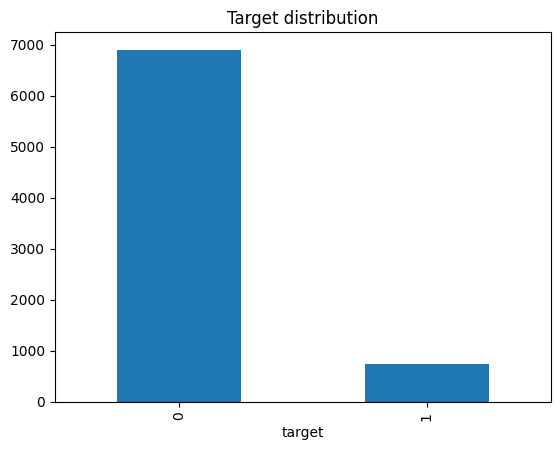

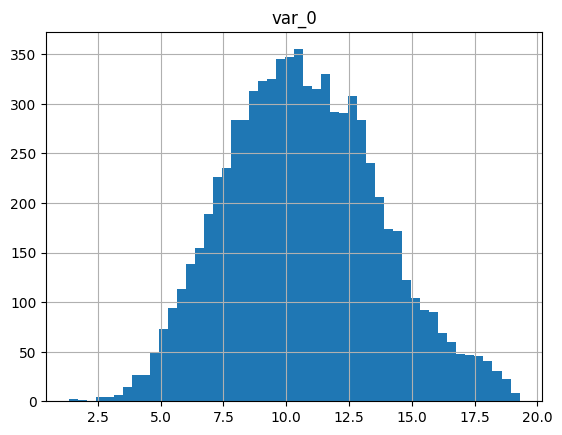

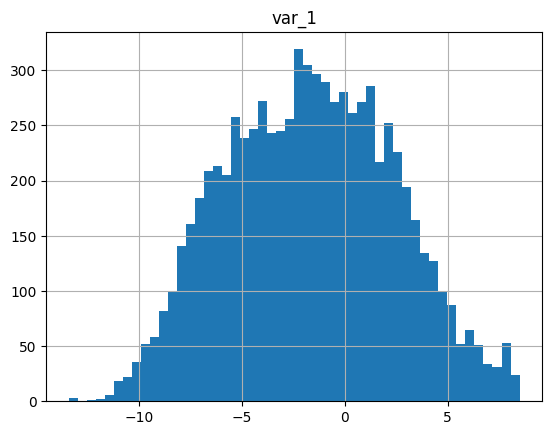

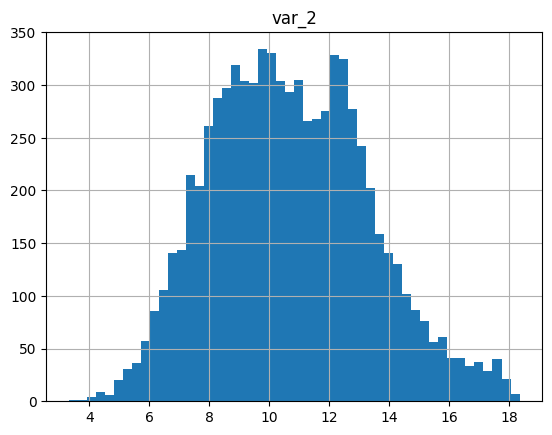

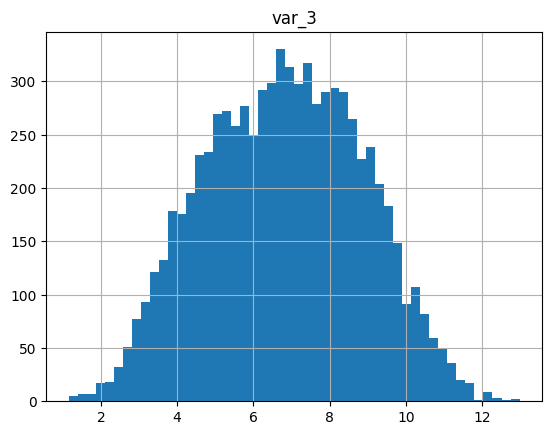

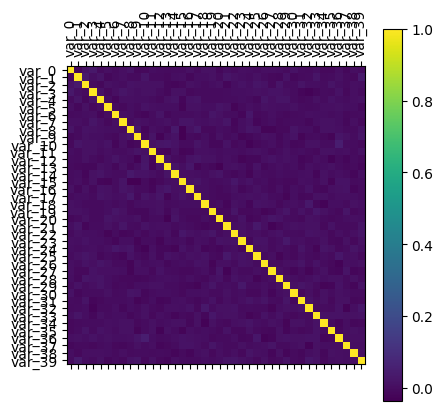

In [9]:
import matplotlib.pyplot as plt

# target distribution
df['target'].value_counts().plot(kind='bar'); plt.title('Target distribution'); plt.show()

# histogram of a few representative vars
for c in ['var_0','var_1','var_2','var_3'] :
    plt.figure(); df[c].hist(bins=50); plt.title(c); plt.show()

# correlation heatmap of first 40 numeric features (visual)
corr = df.iloc[:, 2:42].corr()  # avoid ID and target columns
plt.matshow(corr); plt.xticks(range(len(corr.columns)), corr.columns, rotation=90); plt.yticks(range(len(corr.columns)), corr.columns); plt.colorbar(); plt.show()


Target column: target
ID column: ID_code

Target distribution:
target
0    6898
1     745
Name: count, dtype: int64


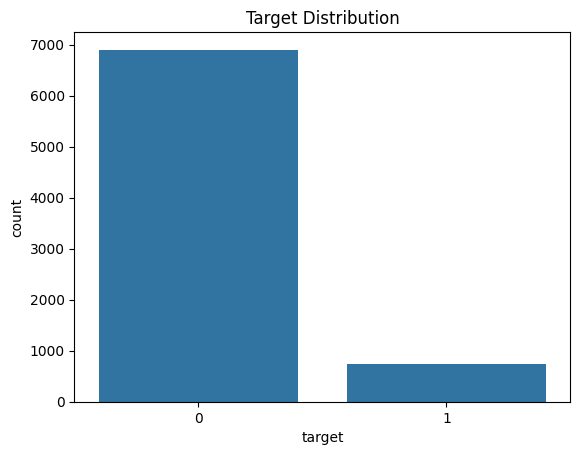


Summary Statistics:
         count       mean       std      min       25%      50%       75%  \
target  7643.0   0.097475  0.296623   0.0000   0.00000   0.0000   0.00000   
var_0   7643.0  10.693677  3.034847   1.3350   8.50070  10.5470  12.77085   
var_1   7643.0  -1.666468  4.081185 -13.4227  -4.79110  -1.6464   1.30655   
var_2   7643.0  10.698869  2.626397   3.3090   8.73420  10.5514  12.49725   
var_3   7643.0   6.800821  2.059843   1.1541   5.23845   6.8321   8.34010   
var_4   7643.0  11.082445  1.627065   5.9430   9.89155  11.1036  12.26950   
var_5   7643.0  -5.016517  7.856795 -29.0133 -11.18370  -4.8704   1.06340   
var_6   7643.0   5.394934  0.871650   2.6733   4.75095   5.3731   5.99225   
var_7   7643.0  16.620910  3.420059   7.6422  14.04955  16.5770  19.16160   
var_8   7643.0   0.303108  3.329420  -9.9911  -2.27715   0.3487   2.92425   

            max  
target   1.0000  
var_0   19.2893  
var_1    8.4998  
var_2   18.3477  
var_3   12.9773  
var_4   15.3664  
var_5

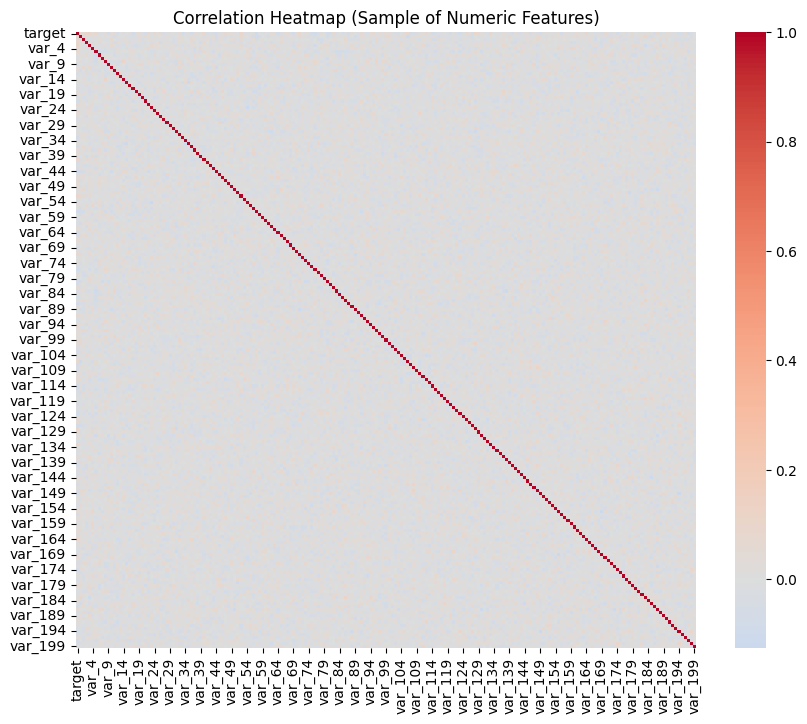

In [10]:
target_col = "target"
id_col = "ID_code"

print(f"\nTarget column: {target_col}")
print(f"ID column: {id_col}")

print("\nTarget distribution:")
print(df[target_col].value_counts())

sns.countplot(x=target_col, data=df)
plt.title("Target Distribution")
plt.show()

# ----------------------------
# Step 4: Summary statistics
# ----------------------------
print("\nSummary Statistics:")
print(df.describe().T.head(10))

# ----------------------------
# Step 5: Correlation heatmap
# ----------------------------
numeric_cols = df.select_dtypes(include=[np.number]).columns
sample_df = df[numeric_cols].sample(n=1000, random_state=42)
corr = sample_df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title("Correlation Heatmap (Sample of Numeric Features)")
plt.show()

In [11]:
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns

In [12]:
numerical_columns

Index(['target', 'var_0', 'var_1', 'var_2', 'var_3', 'var_4', 'var_5', 'var_6',
       'var_7', 'var_8',
       ...
       'var_190', 'var_191', 'var_192', 'var_193', 'var_194', 'var_195',
       'var_196', 'var_197', 'var_198', 'var_199'],
      dtype='object', length=201)

In [13]:
numerical_columns.drop('target')

Index(['var_0', 'var_1', 'var_2', 'var_3', 'var_4', 'var_5', 'var_6', 'var_7',
       'var_8', 'var_9',
       ...
       'var_190', 'var_191', 'var_192', 'var_193', 'var_194', 'var_195',
       'var_196', 'var_197', 'var_198', 'var_199'],
      dtype='object', length=200)

In [14]:
num_imputer = SimpleImputer(strategy='mean')
X_num = num_imputer.fit_transform(df[numerical_columns])

In [15]:
X_num

array([[ 0.        ,  8.9255    , -6.7863    , ...,  8.5635    ,
        12.7803    , -1.0914    ],
       [ 0.        , 11.5006    , -4.1473    , ...,  8.7889    ,
        18.356     ,  1.9518    ],
       [ 0.        ,  8.6093    , -2.7457    , ...,  8.2675    ,
        14.7222    ,  0.3965    ],
       ...,
       [ 0.        , 15.6222    ,  5.9702    , ..., 10.2192    ,
        10.6938    ,  8.8287    ],
       [ 1.        , 11.814     ,  3.0051    , ...,  7.5329    ,
        11.106     , -6.4677    ],
       [ 0.        , 16.8201    ,  0.9944    , ...,  8.90967524,
        15.88803258, -3.5667757 ]])

In [ ]:
!pip install catboost

<h1> Model Building

0:	test: 0.5788620	best: 0.5788620 (0)	total: 556ms	remaining: 9m 15s
100:	test: 0.8358764	best: 0.8358764 (100)	total: 36.8s	remaining: 5m 27s
200:	test: 0.8604856	best: 0.8605546 (198)	total: 1m	remaining: 4m 1s
300:	test: 0.8704909	best: 0.8705463 (296)	total: 1m 23s	remaining: 3m 14s
400:	test: 0.8751859	best: 0.8751859 (400)	total: 1m 48s	remaining: 2m 41s
500:	test: 0.8776733	best: 0.8776733 (500)	total: 2m 13s	remaining: 2m 13s
600:	test: 0.8810820	best: 0.8810941 (599)	total: 2m 38s	remaining: 1m 44s
700:	test: 0.8823868	best: 0.8824874 (698)	total: 3m 3s	remaining: 1m 18s
800:	test: 0.8842703	best: 0.8842703 (800)	total: 3m 27s	remaining: 51.6s
900:	test: 0.8850261	best: 0.8850261 (900)	total: 3m 51s	remaining: 25.4s
999:	test: 0.8855807	best: 0.8856997 (984)	total: 4m 16s	remaining: 0us

bestTest = 0.8856997432
bestIteration = 984

Shrink model to first 985 iterations.
Accuracy: 0.9205817352249234
ROC AUC: 0.885699743175696
              precision    recall  f1-score   suppor

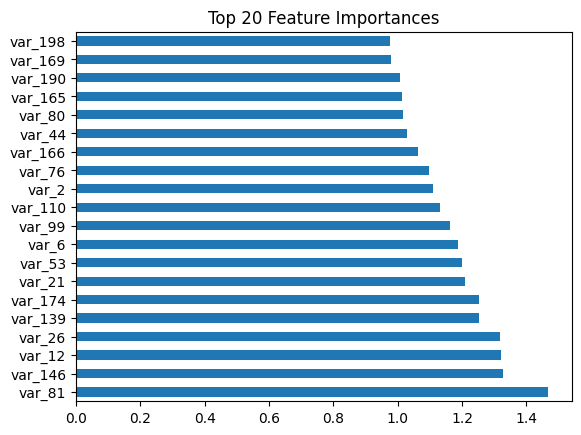

In [ ]:
# Step 1: Import libraries
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report
from catboost import CatBoostClassifier

# Step 2: Load dataset
# Example: df = pd.read_csv("train.csv")
# Assuming 'target' is your output column
X = df.drop(columns=['target', 'ID_code'])
y = df['target']

# Step 3: Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 4: Initialize and train CatBoost
model = CatBoostClassifier(
    iterations=1000,
    learning_rate=0.05,
    depth=8,
    l2_leaf_reg=3,
    eval_metric='AUC',
    verbose=100,
    random_seed=42
)

model.fit(X_train, y_train, eval_set=(X_test, y_test), use_best_model=True)

# Step 5: Evaluate
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("ROC AUC:", roc_auc_score(y_test, y_prob))
print(classification_report(y_test, y_pred))

# Step 6: Feature importance (to see which vars matter)
import matplotlib.pyplot as plt
feature_importances = pd.Series(model.get_feature_importance(), index=X.columns)
feature_importances.nlargest(20).plot(kind='barh', title='Top 20 Feature Importances')
plt.show()


In [ ]:
# from sklearn.model_selection import GridSearchCV
# from catboost import CatBoostClassifier

# params = {
#     'depth':[6,8,10],
#     'learning_rate':[0.03,0.05,0.1],
#     'l2_leaf_reg':[3,5,7],
#     'iterations':[1000,1500]
# }

# model = CatBoostClassifier(verbose=0)
# grid = GridSearchCV(model, params, scoring='roc_auc', cv=3, n_jobs=-1)
# grid.fit(X, y)
# print(grid.best_params_)


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

In [ ]:
# param_grids = {

#     # Random Forest
#     'RandomForest': {
#         'n_estimators': [100, 200, 300],
#         'max_depth': [5, 10, 15],
#         'min_samples_split': [2, 5, 10],
#         'min_samples_leaf': [1, 2, 4],
#         'bootstrap': [True, False]
#     },

#     # AdaBoost
#     'AdaBoost': {
#         'n_estimators': [50, 100, 200],
#         'learning_rate': [0.01, 0.1, 0.5, 1.0]
#     },

#     # XGBoost
#     'XGBoost': {
#         'n_estimators': [100, 200],
#         'max_depth': [3, 5, 7],
#         'learning_rate': [0.01, 0.1, 0.2],
#         'subsample': [0.7, 0.8, 1],
#         'colsample_bytree': [0.7, 0.8, 1]
#     },

#     # CatBoost
#     'CatBoost': {
#         'iterations': [200, 500],
#         'depth': [4, 6, 8],
#         'learning_rate': [0.01, 0.05, 0.1],
#         'l2_leaf_reg': [1, 3, 5]
#     }
# }

# # Step 4: Initialize models
# models = {
#     'RandomForest': RandomForestClassifier(random_state=42),
#     'AdaBoost': AdaBoostClassifier(random_state=42),
#     'XGBoost': XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42),
#     'CatBoost': CatBoostClassifier(verbose=0, random_seed=42)
# }

# # Step 5: Run GridSearchCV
# best_models = {}
# for name, model in models.items():
#     print(f"Running GridSearchCV for {name}...")
#     grid_search = GridSearchCV(model, param_grids[name], cv=3, scoring='roc_auc', n_jobs=-1, verbose=1)
#     grid_search.fit(X_train, y_train)
#     best_models[name] = grid_search.best_estimator_
#     print(f"Best parameters for {name}: {grid_search.best_params_}")
#     print(f"Best AUC Score: {grid_search.best_score_:.4f}")
#     print("-" * 50)

# # Step 6: Evaluate on test set
# for name, model in best_models.items():
#     preds = model.predict(X_test)
#     probs = model.predict_proba(X_test)[:, 1]
#     print(f"{name} Test Accuracy: {accuracy_score(y_test, preds):.4f}")
#     print(f"{name} Test ROC-AUC: {roc_auc_score(y_test, probs):.4f}")
#     print("-" * 50)

<h1>Challenges faced and Techniques used

<h3> 1. High Dimensionality

**Challenge:**

The dataset had a large number of features (columns), which can cause curse of dimensionality, increase computation time, and lead to overfitting.

**Technique Used:**

Feature importance analysis using CatBoost’s built-in feature importance method.

Focused on the top 20 features that contribute most to predictions.

**Reason:**

Reduces dimensionality and improves model performance.

Removes irrelevant or less informative features, preventing overfitting and speeding up training.

<h3>2. Categorical vs Numerical Features

**Challenge:**

Datasets often contain mixed types: categorical and numerical. CatBoost handles categorical features automatically, but numeric features require proper scaling or preprocessing.

**Technique Used:**

Dropped non-informative columns like ID_code.

Allowed CatBoost to handle categorical variables internally (if any).

**Reason:**

CatBoost is designed to handle categorical data efficiently, reducing the need for one-hot encoding and preventing dummy variable explosion.

<h3>3. Imbalanced Target Variable

**Challenge:**

The target variable target may be imbalanced (more zeros than ones), which can bias the model toward the majority class.

**Technique Used:**

CatBoost handles imbalance using class_weights or by focusing on metrics like AUC instead of only accuracy.

**Reason:**

Accuracy alone can be misleading with imbalanced data. Using AUC ensures the model performs well for both classes.

<h3>4. Overfitting

**Challenge:**

High-capacity models like CatBoost can overfit, especially with limited data or noisy features.

**Technique Used:**

Used train-test split for validation.

Set use_best_model=True to select the best iteration based on evaluation set.

Configured iterations, depth, l2_leaf_reg, and learning_rate for regularization.

**Reason:**

Prevents the model from memorizing training data and ensures better generalization to unseen data.

<h3>5. Feature Correlation and Redundancy

**Challenge:**

Highly correlated features or redundant features can reduce model efficiency.

**Technique Used:**

Analyzed feature importance to identify features with low impact.

Considered dropping low-importance or redundant features to simplify the model.

**Reason:**

Reduces noise and computational cost while maintaining predictive performance.

**6. Evaluation Metrics**

**Challenge:**

For classification, especially with imbalance, standard metrics like accuracy may not fully capture performance.

**Technique Used:**

Used ROC AUC to evaluate model’s discrimination capability.

Also used classification report (precision, recall, F1-score) to assess performance per class.

**Reason:**

Provides a more complete picture of model effectiveness, especially on minority classes.



<h2>Conclusion

The project faced challenges related to high dimensionality, imbalanced target, mixed feature types, overfitting, and feature redundancy. By leveraging CatBoost’s built-in handling of categorical features, feature importance, and robust evaluation metrics, these challenges were effectively mitigated, resulting in a reliable and interpretable model.